# Lab 28-02 · Restating Claims on a Common Basis

Companion to [chapter 28-02](../../chapters/28-02-validating-claims.md). Every part asks you to **predict first**, then run. Parameters are the chapter's assumptions unless a source is cited there.

In [1]:
import sys, math, random
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, '.')
import claimcheck as cc
peak = cc.peak_ops(cc.NPU_MACS, cc.NPU_CLOCK)
print(f"dense INT8 peak = {peak/1e12:.1f} TOPS, headline (x2) = {2*peak/1e12:.0f} TOPS")

dense INT8 peak = 78.6 TOPS, headline (x2) = 157 TOPS


## Part 1 · The roofline under the headline

**Predict:** attainable throughput and utilization at 300 operations per byte with 64 GB/s.

In [2]:
att = cc.roofline_ops(peak, cc.NPU_BW, 300)
print(f"ridge = {peak/cc.NPU_BW:.0f} ops/byte; attainable = {att/1e12:.1f} TOPS ({100*att/peak:.1f}% of peak)")

ridge = 1229 ops/byte; attainable = 19.2 TOPS (24.4% of peak)


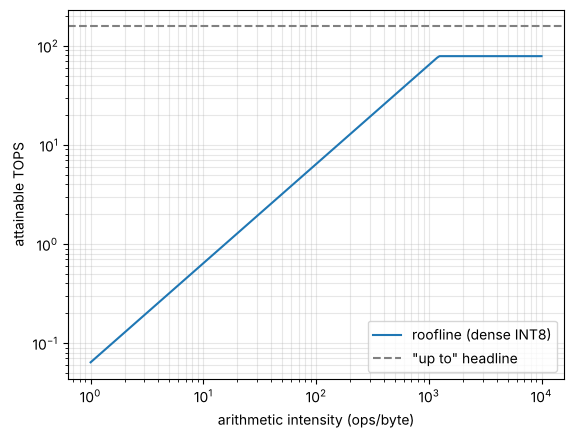

In [3]:
I = np.logspace(0, 4, 200)
plt.loglog(I, [cc.roofline_ops(peak, cc.NPU_BW, x)/1e12 for x in I], label='roofline (dense INT8)')
plt.axhline(2*peak/1e12, color='grey', ls='--', label='"up to" headline')
plt.xlabel('arithmetic intensity (ops/byte)'); plt.ylabel('attainable TOPS'); plt.legend(); plt.grid(True, which='both', alpha=0.3); plt.show()

## Part 2 · Along the voltage–frequency line

Example 28-02.3: 80 TOPS at 4.0 W at (0.60 V, 400 MHz); dynamic power only.

**Predict:** throughput, power and efficiency at (0.75 V, 700 MHz).

In [4]:
def point(v, f):
    p = cc.scale_dynamic_power(4.0, 0.60, 0.4e9, v, f)
    t = 80 * f / 0.4e9
    return t, p, t / p
t, p, e = point(0.75, 0.7e9)
print(f"{t:.0f} TOPS, {p:.2f} W, {e:.1f} TOPS/W")

140 TOPS, 10.94 W, 12.8 TOPS/W


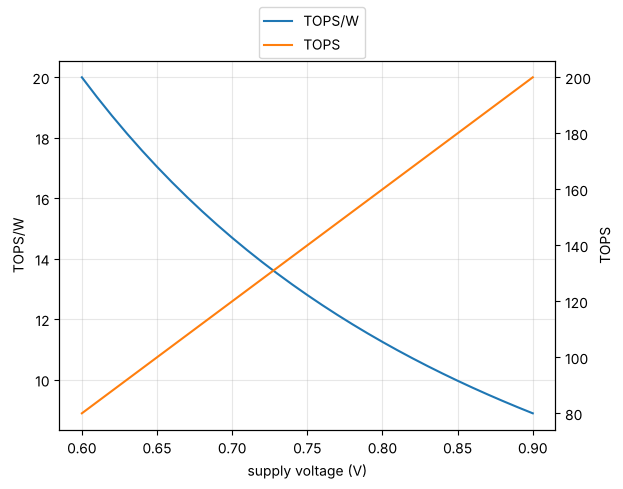

In [5]:
vs = np.linspace(0.60, 0.90, 31)
fs = 0.4e9 + (vs - 0.60) / 0.30 * 0.6e9
pts = [point(v, f) for v, f in zip(vs, fs)]
fig, ax = plt.subplots(); ax.plot(vs, [x[2] for x in pts], label='TOPS/W'); ax.set_xlabel('supply voltage (V)'); ax.set_ylabel('TOPS/W')
ax2 = ax.twinx(); ax2.plot(vs, [x[0] for x in pts], 'C1', label='TOPS'); ax2.set_ylabel('TOPS')
fig.legend(loc='upper center'); ax.grid(True, alpha=0.3); plt.show()

## Part 3 · Best of twenty

**Predict:** the expected best of twenty workloads for median 1.5× and log spread 0.3.

E[max of 20] = 1.867; formula best = 2.63x


simulated mean best = 2.66x (median 2.59x)


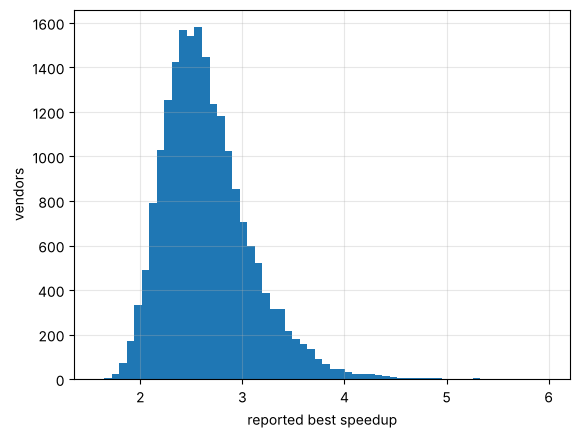

In [6]:
print(f"E[max of 20] = {cc.expected_max_std_normal(20):.3f}; formula best = {cc.best_of_n(1.5, 0.3, 20):.2f}x")
rng = random.Random(11)
bests = [1.5 * math.exp(max(rng.gauss(0, 0.3) for _ in range(20))) for _ in range(20000)]
print(f"simulated mean best = {np.mean(bests):.2f}x (median {np.median(bests):.2f}x)")
plt.hist(bests, bins=60); plt.xlabel('reported best speedup'); plt.ylabel('vendors'); plt.grid(True, alpha=0.3); plt.show()

## Part 4 · A metal-only respin

Example 28-02.6: masks 3, fab 16, packaging and test 4, bring-up 12 weeks; qualification 1000 h plus 2 weeks.

**Predict:** the time to production with one metal-only respin (2 weeks of masks, 6 of fab).

In [7]:
w = cc.tapeout_to_production(3, 16, 4, 12, 1, 2, 6, 1000, 2)
print(f"{w:.1f} weeks = {cc.weeks_to_months(w):.1f} months")

55.0 weeks = 12.6 months


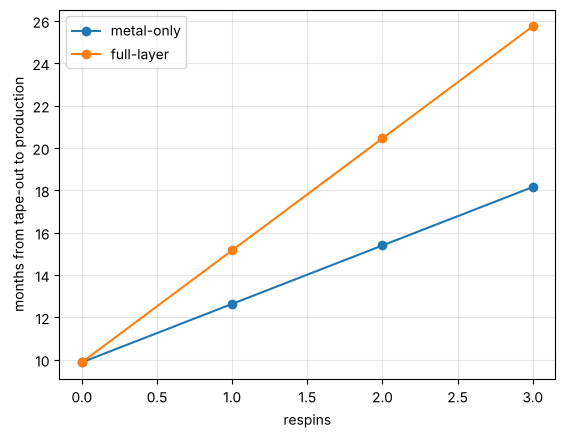

In [8]:
n = range(4)
for lab, mk, fb in (('metal-only', 2, 6), ('full-layer', 3, 16)):
    plt.plot(list(n), [cc.weeks_to_months(cc.tapeout_to_production(3, 16, 4, 12, k, mk, fb, 1000, 2)) for k in n], 'o-', label=lab)
plt.xlabel('respins'); plt.ylabel('months from tape-out to production'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()